# PROJECT OBJECTIVE

To identify and group countries based on gender inequality indicators and understand the differences in reproductive health, educational empowerment and economic participation across these groups.

# EDA

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")


In [2]:
df = pd.read_csv("/content/Gender_Inequality_Index.csv")
df.head()

,Country,Human_development,GII,Rank,Maternal_mortality,Adolescent_birth_rate,Seats_parliament,F_secondary_educ,M_secondary_educ,F_Labour_force,M_Labour_force
0,Switzerland,Very high,0.018,3.0,5.0,2.2,39.8,96.9,97.5,61.7,72.7
1,Norway,Very high,0.016,2.0,2.0,2.3,45.0,99.1,99.3,60.3,72.0
2,Iceland,Very high,0.043,8.0,4.0,5.4,47.6,99.8,99.7,61.7,70.5
3,Hong Kong,Very high,NaN,NaN,NaN,1.6,NaN,77.1,83.4,53.5,65.8
4,Australia,Very high,0.073,19.0,6.0,8.1,37.9,94.6,94.4,61.1,70.5


In [3]:
df

,Country,Human_development,GII,Rank,Maternal_mortality,Adolescent_birth_rate,Seats_parliament,F_secondary_educ,M_secondary_educ,F_Labour_force,M_Labour_force
0,Switzerland,Very high,0.018,3.0,5.0,2.2,39.8,96.9,97.5,61.7,72.7
1,Norway,Very high,0.016,2.0,2.0,2.3,45.0,99.1,99.3,60.3,72.0
2,Iceland,Very high,0.043,8.0,4.0,5.4,47.6,99.8,99.7,61.7,70.5
3,Hong Kong,Very high,NaN,NaN,NaN,1.6,NaN,77.1,83.4,53.5,65.8
4,Australia,Very high,0.073,19.0,6.0,8.1,37.9,94.6,94.4,61.1,70.5
...,...,...,...,...,...,...,...,...,...,...,...
190,South Sudan,Low,0.587,150.0,1150.0,99.2,32.3,26.5,36.4,70.4,73.6
191,North Korea,NaN,NaN,NaN,89.0,2.3,17.6,NaN,NaN,77.2,86.1
192,Monaco,NaN,NaN,NaN,NaN,7.2,33.3,NaN,NaN,NaN,NaN
193,Nauru,NaN,NaN,NaN,NaN,72.5,10.5,NaN,NaN,NaN,NaN


In [4]:
df.shape

(195, 11)

In [5]:
df.size

2145

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Country                195 non-null    object 
 1   Human_development      191 non-null    object 
 2   GII                    170 non-null    float64
 3   Rank                   170 non-null    float64
 4   Maternal_mortality     184 non-null    float64
 5   Adolescent_birth_rate  195 non-null    float64
 6   Seats_parliament       193 non-null    float64
 7   F_secondary_educ       177 non-null    float64
 8   M_secondary_educ       177 non-null    float64
 9   F_Labour_force         180 non-null    float64
 10  M_Labour_force         180 non-null    float64
dtypes: float64(9), object(2)
memory usage: 16.9+ KB


In [7]:
df['Human_development'].unique()

array(['Very high', 'High', 'Medium', 'Low', nan], dtype=object)

In [8]:
df.dtypes

,0
Country,object
Human_development,object
GII,float64
Rank,float64
Maternal_mortality,float64
Adolescent_birth_rate,float64
Seats_parliament,float64
F_secondary_educ,float64
M_secondary_educ,float64
F_Labour_force,float64




*   The Gender Inequality Index dataset has 2145 elements which consist of 195 rows and 11 columns.
*  The Column Human Developent has 4 unique values



# Data Preprocessing

In [9]:
#Checking null values
df.isnull().sum()

,0
Country,0
Human_development,4
GII,25
Rank,25
Maternal_mortality,11
Adolescent_birth_rate,0
Seats_parliament,2
F_secondary_educ,18
M_secondary_educ,18
F_Labour_force,15


In [10]:
#Null Value Percentage
(df.isnull().sum()/len(df))*100

,0
Country,0.000000
Human_development,2.051282
GII,12.820513
Rank,12.820513
Maternal_mortality,5.641026
Adolescent_birth_rate,0.000000
Seats_parliament,1.025641
F_secondary_educ,9.230769
M_secondary_educ,9.230769
F_Labour_force,7.692308


In [11]:
#Replacing Human Development with Mode
df['Human_development'].fillna(
    df['Human_development'].mode()[0],
    inplace=True
)

In [12]:
#Replacing every numerical column with median
cols =[
    'GII',
    'Maternal_mortality',
    'Seats_parliament',
    'F_secondary_educ',
    'M_secondary_educ',
    'F_Labour_force',
    'M_Labour_force'
]
for col in cols:
    df[col].fillna(
        df[col].median(),
        inplace=True
    )

In [13]:
#Dropping Rank
df.drop(columns = ['Rank'],inplace=True)

In [14]:
#Checking missing values after handling it
df.isnull().sum()

,0
Country,0
Human_development,0
GII,0
Maternal_mortality,0
Adolescent_birth_rate,0
Seats_parliament,0
F_secondary_educ,0
M_secondary_educ,0
F_Labour_force,0
M_Labour_force,0


In [15]:
#Check Duplicate values
df.duplicated().sum()

np.int64(0)

In [16]:
df.head()

,Country,Human_development,GII,Maternal_mortality,Adolescent_birth_rate,Seats_parliament,F_secondary_educ,M_secondary_educ,F_Labour_force,M_Labour_force
0,Switzerland,Very high,0.018,5.0,2.2,39.8,96.9,97.5,61.7,72.7
1,Norway,Very high,0.016,2.0,2.3,45.0,99.1,99.3,60.3,72.0
2,Iceland,Very high,0.043,4.0,5.4,47.6,99.8,99.7,61.7,70.5
3,Hong Kong,Very high,0.363,53.0,1.6,23.6,77.1,83.4,53.5,65.8
4,Australia,Very high,0.073,6.0,8.1,37.9,94.6,94.4,61.1,70.5


In [17]:
#Conevrting the Human_developent column into Ordinal Encoding using mapping
development_mapping = {
    'Low' : 1,
    'Medium' : 2,
    'High': 3,
    'Very high': 4
}

df['Human_development'] = df['Human_development'].map(development_mapping)

In [18]:
df['Human_development'].value_counts()

,count
Human_development,
4,70
3,49
2,44
1,32


In [19]:
df.dtypes

,0
Country,object
Human_development,int64
GII,float64
Maternal_mortality,float64
Adolescent_birth_rate,float64
Seats_parliament,float64
F_secondary_educ,float64
M_secondary_educ,float64
F_Labour_force,float64
M_Labour_force,float64


In [20]:
df['Human_development'].unique()

array([4, 3, 2, 1])

In [21]:
df.describe()

,Human_development,GII,Maternal_mortality,Adolescent_birth_rate,Seats_parliament,F_secondary_educ,M_secondary_educ,F_Labour_force,M_Labour_force
count,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000,195.000000
mean,2.805128,0.346764,153.989744,44.597949,24.690256,63.370769,67.449744,50.372564,69.823846
std,1.099660,0.184073,227.675886,38.422479,12.340715,28.202631,25.221621,15.286877,8.658381
min,1.000000,0.013000,2.000000,1.600000,0.000000,6.400000,13.000000,6.000000,43.900000
25%,2.000000,0.201500,15.500000,10.750000,16.600000,40.950000,49.050000,43.350000,65.500000
50%,3.000000,0.363000,53.000000,36.200000,23.600000,69.900000,71.200000,52.150000,69.350000
75%,4.000000,0.485500,180.000000,64.200000,33.450000,88.350000,91.250000,59.500000,75.250000
max,4.000000,0.820000,1150.000000,170.500000,55.700000,100.000000,100.000000,83.100000,95.500000


1. The Large difference between mean and median of Maternal_mortality possibly suggests possible outleirs or highly skewed distribution.
2. Male labour force participation (69.82%) is higher than female participation (50.37%) on average.

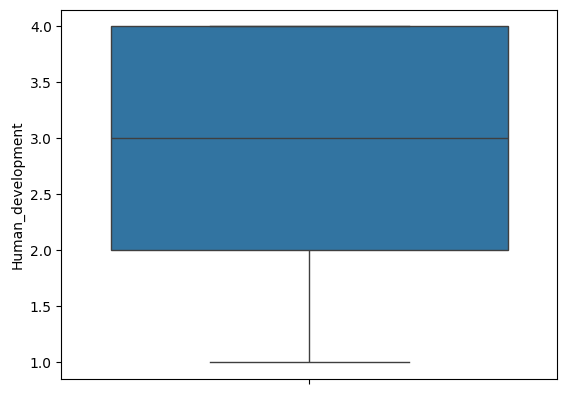

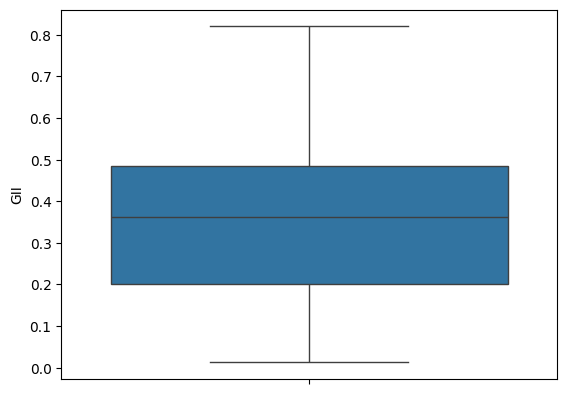

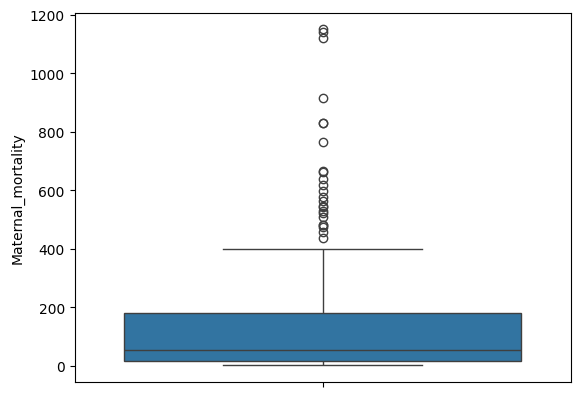

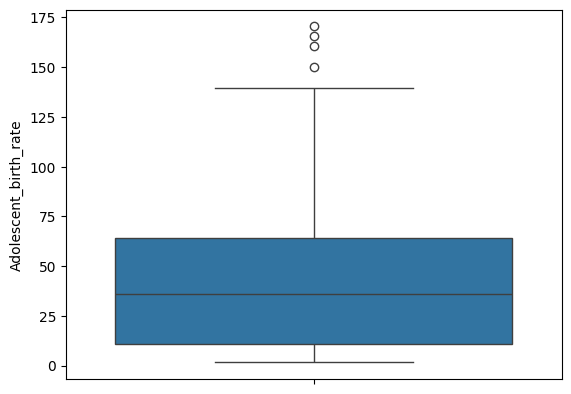

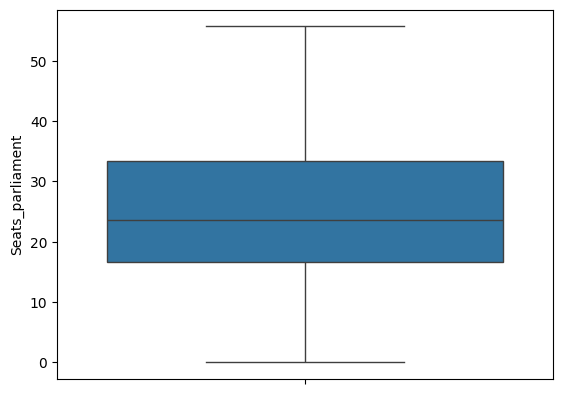

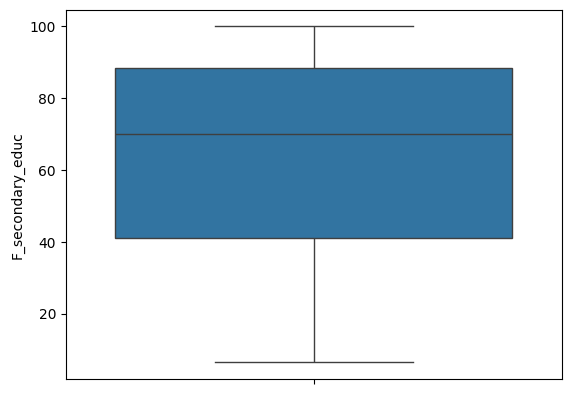

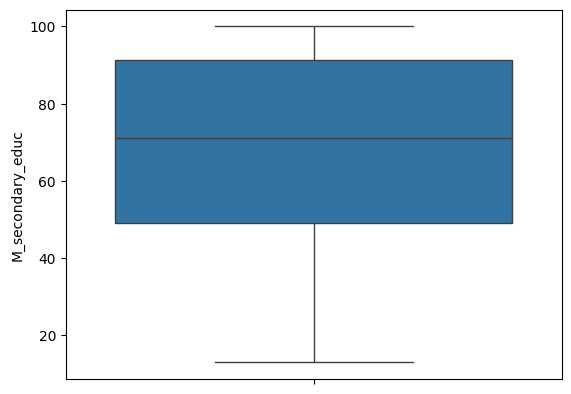

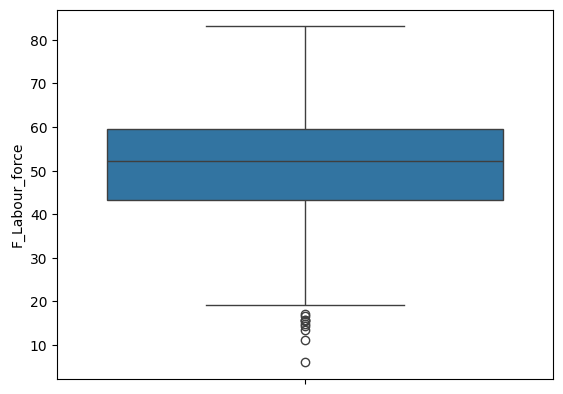

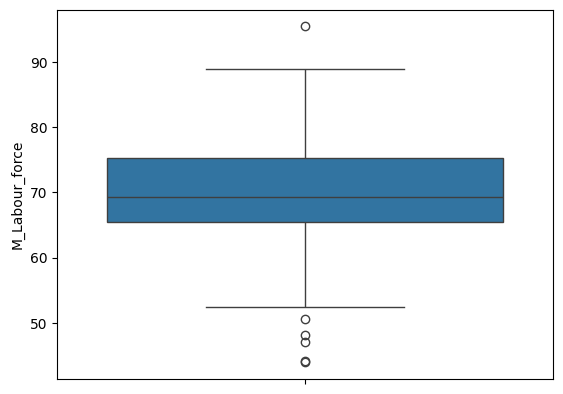

In [22]:
#Check outliers
for i in df.select_dtypes(include=['int','float']).columns:
    sns.boxplot(df[i])
    plt.show()


In [23]:
#Removing outliers
for i in df.select_dtypes(include=['int','float']).columns:
  q1 = df[i].quantile(0.25)
  q3 = df[i].quantile(0.75)
  IQR = q3-q1
  lower_bound = q1 - 1.5 * IQR
  upper_bound = q3 + 1.5 * IQR
  df[i] = df[i].clip(lower_bound, upper_bound)

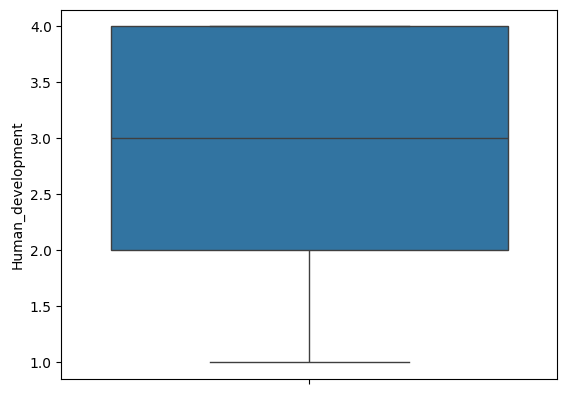

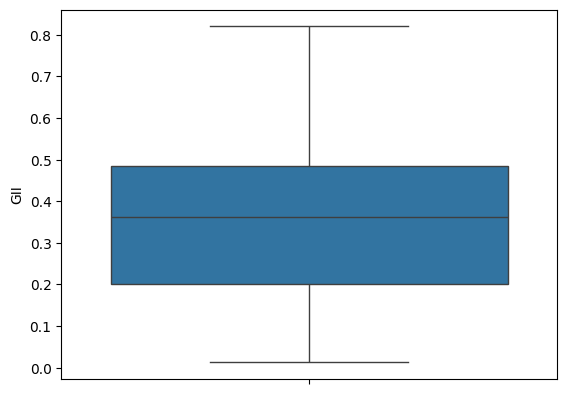

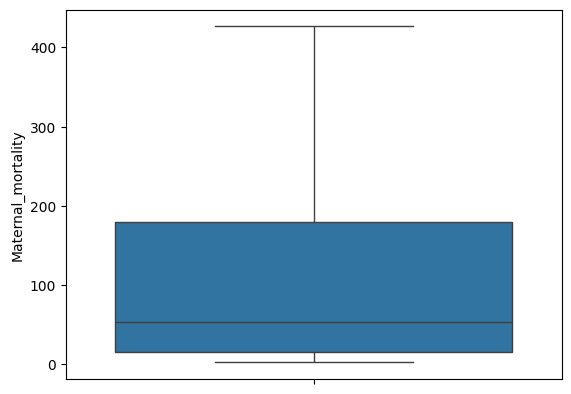

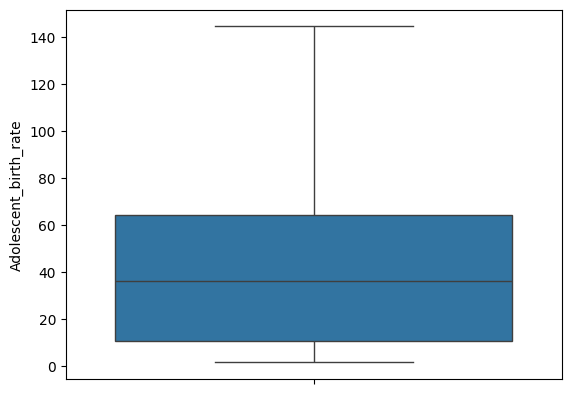

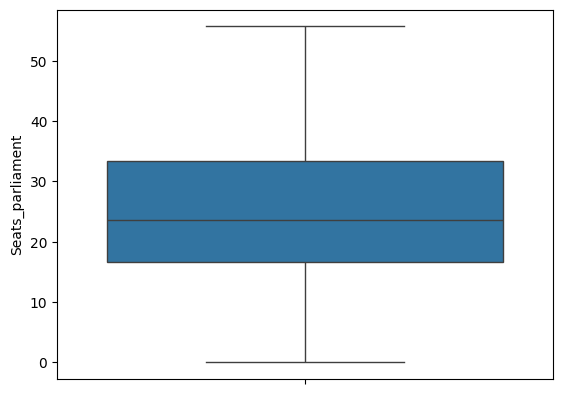

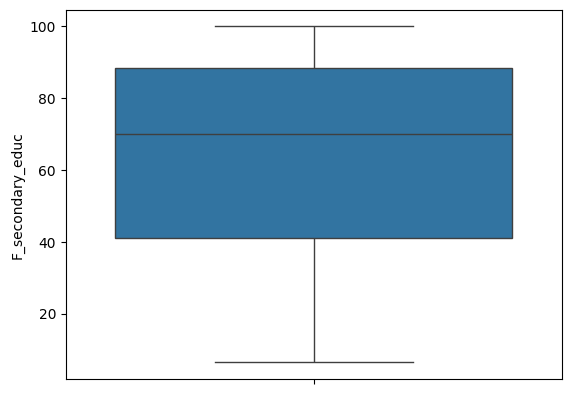

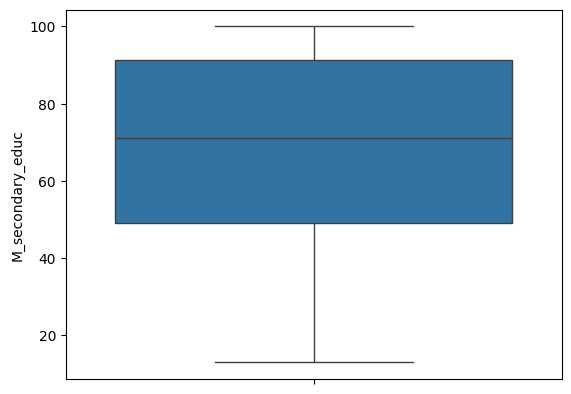

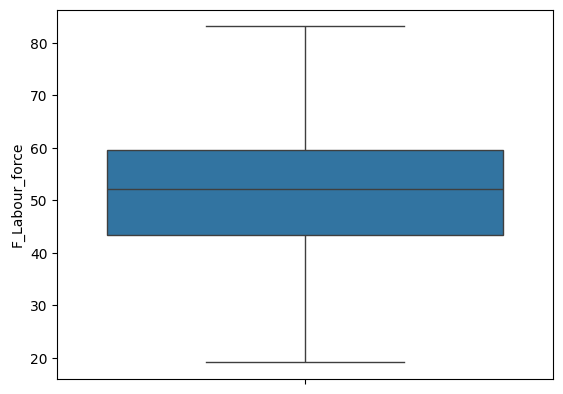

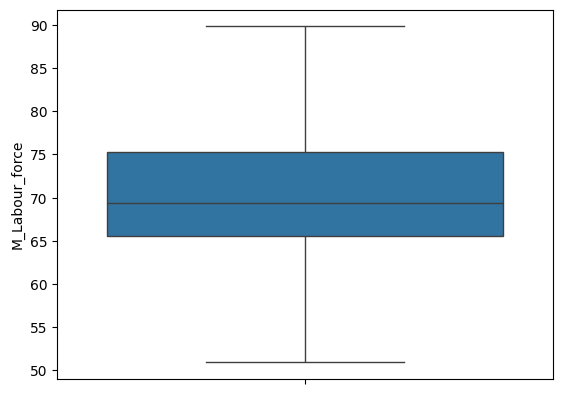

In [24]:
#Check outliers after handling it
for i in df.select_dtypes(include=['int','float']).columns:
  sns.boxplot(df[i])
  plt.show()

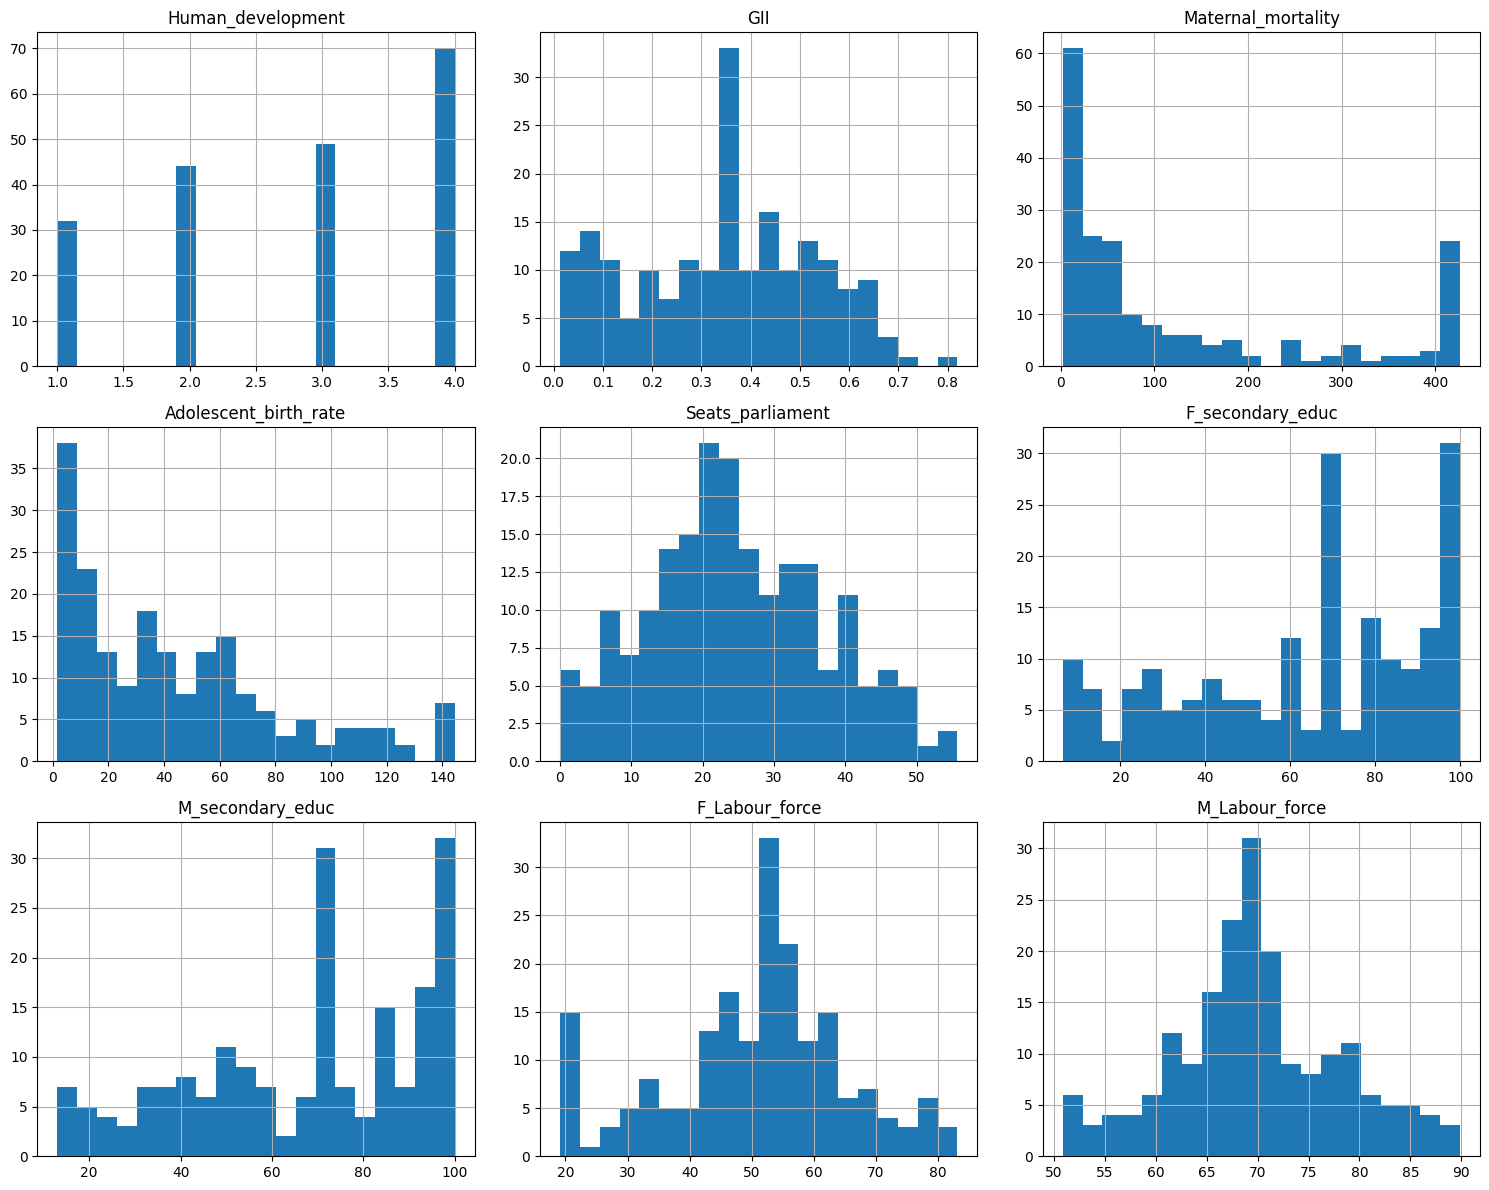

In [25]:
#Univariate Analysis

df.hist(figsize=(15,12), bins = 20)
plt.tight_layout()
plt.show()

**Bi-Variate Analysis**

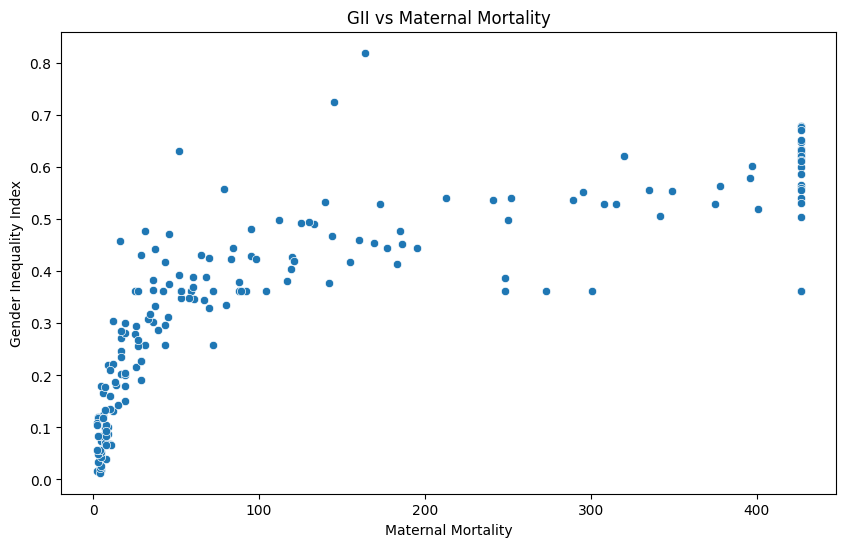

In [26]:
#Visualising the relationship between the GII and Maternal_mortality
plt.figure(figsize=(10,6))
sns.scatterplot(
    data = df,
    x = 'Maternal_mortality',
    y = 'GII'
)
plt.title("GII vs Maternal Mortality")
plt.xlabel("Maternal Mortality")
plt.ylabel("Gender Inequality Index")
plt.show()

In [27]:
df[['GII','Maternal_mortality']].corr()

,GII,Maternal_mortality
GII,1.000000,0.769427
Maternal_mortality,0.769427,1.000000


"Maternal mortality and Gender Inequality Index show a strong positive correlation of 0.7694. This indicates that countries with higher Maternal mortality rates generally tend to experience higher gender inequality. Therefore, Reproductive health is an important dimension to investigate when understanding gender inequality across countries.

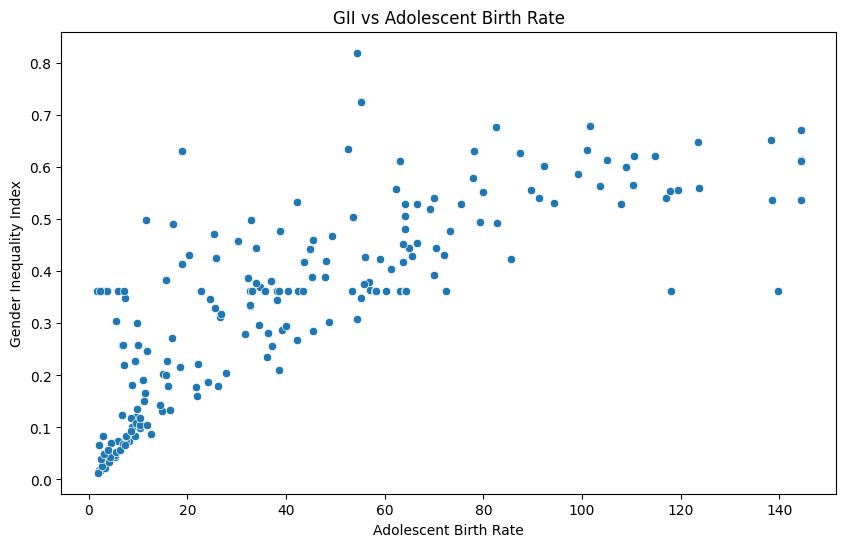

In [28]:
# Visualising the relationship between the GII and Adolescent_birt_rate
plt.figure(figsize=(10,6))
sns.scatterplot(
    data = df,
    x = 'Adolescent_birth_rate',
    y = 'GII'
)
plt.title("GII vs Adolescent Birth Rate")
plt.xlabel("Adolescent Birth Rate")
plt.ylabel("Gender Inequality Index")
plt.show()

In [29]:
df[['GII','Adolescent_birth_rate']].corr()

,GII,Adolescent_birth_rate
GII,1.000000,0.773841
Adolescent_birth_rate,0.773841,1.000000


1. The correaltion is postive (0.77)
2. The relationship is strong, indicating that adolescent birthrate is closely associated with gender inequality.



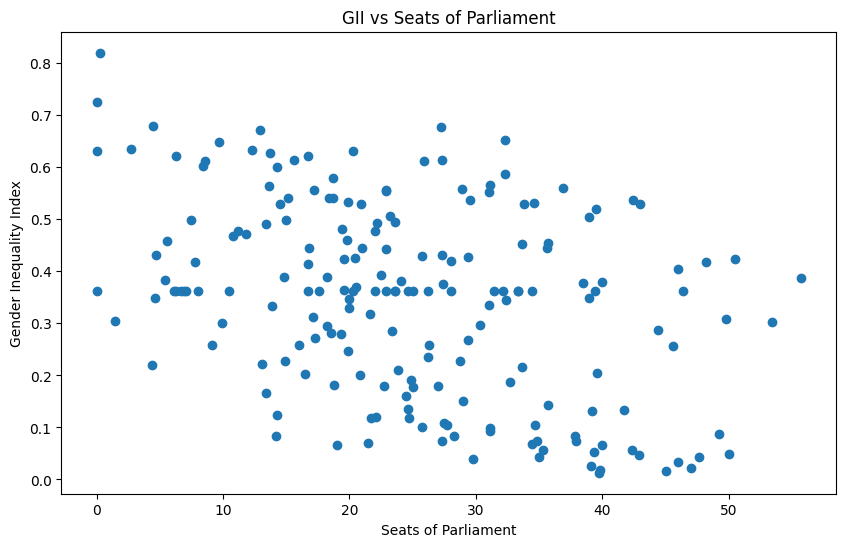

In [30]:
#Visualising the relationship between GII and Seats_parliament
plt.figure(figsize=(10,6))
plt.scatter(
    data = df,
    x = 'Seats_parliament',
    y = 'GII'
)
plt.title("GII vs Seats of Parliament")
plt.xlabel("Seats of Parliament")
plt.ylabel("Gender Inequality Index")
plt.show()

In [31]:
df[['GII','Seats_parliament']].corr()

,GII,Seats_parliament
GII,1.000000,-0.400387
Seats_parliament,-0.400387,1.000000


Seats by held by women in parliament show a moderate negative correlation (-0.400) with GII, suggesting that greater female political representation tends to be associated with lower gender inequality.

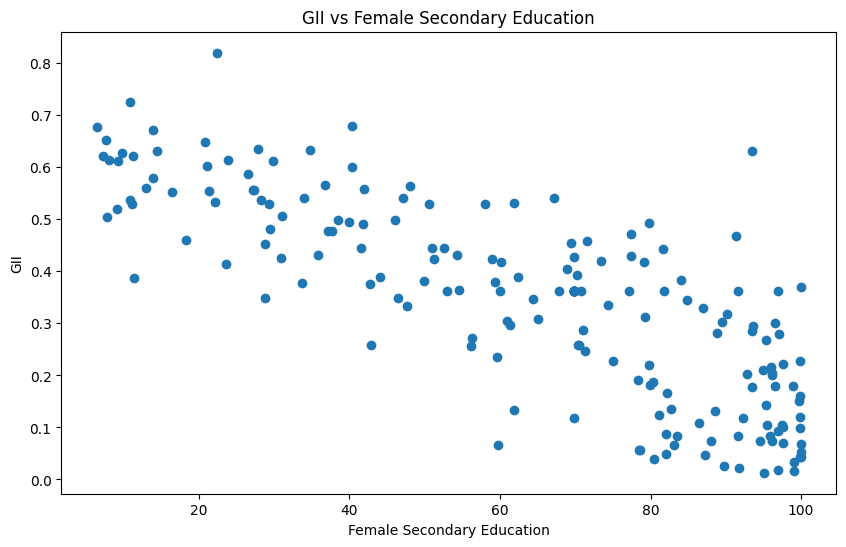

In [32]:
#Visualising the relationship between GII and F_secondary_educ
plt.figure(figsize=(10,6))
plt.scatter(
    data = df,
    x = 'F_secondary_educ',
    y = 'GII'
)
plt.title("GII vs Female Secondary Education")
plt.xlabel("Female Secondary Education")
plt.ylabel("GII")
plt.show()

In [33]:
df[['GII','F_secondary_educ']].corr()

,GII,F_secondary_educ
GII,1.00000,-0.79529
F_secondary_educ,-0.79529,1.00000


Female secondary education has a strong negative correlation (-0.79) with the Gender Inequality Index. This suggests that countries with higher female educational attainment generally experience lower gender inequality.

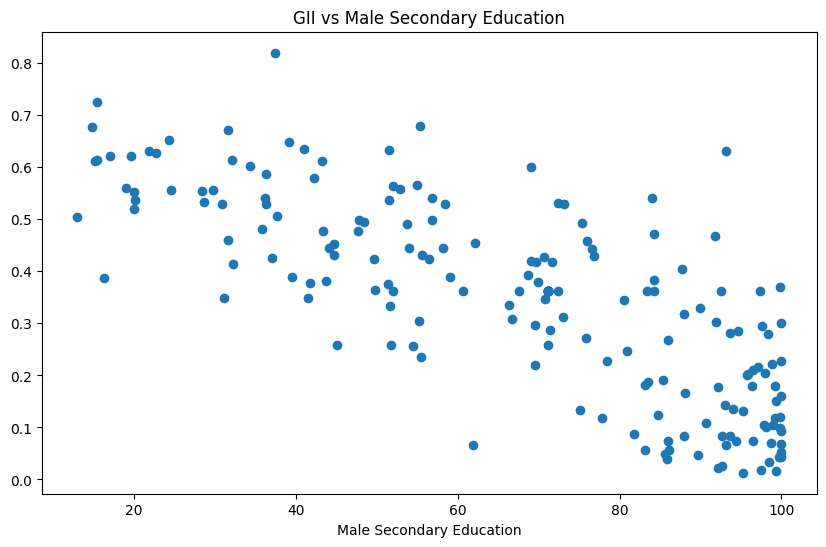

In [34]:
#Visualising the relationship between GII and M_secondary_educ
plt.figure(figsize=(10,6))
plt.scatter(
    data = df,
    x = 'M_secondary_educ',
    y = 'GII'
)
plt.title("GII vs Male Secondary Education")
plt.xlabel("Male Secondary Education")
plt.show()

In [35]:
df[['GII','M_secondary_educ']].corr()

,GII,M_secondary_educ
GII,1.000000,-0.770487
M_secondary_educ,-0.770487,1.000000


The correlation of GII vs Male secondary eductaion indicated a strong negative correlation of (-0.77).

Means as the Male secondary education increases the GII decreases.

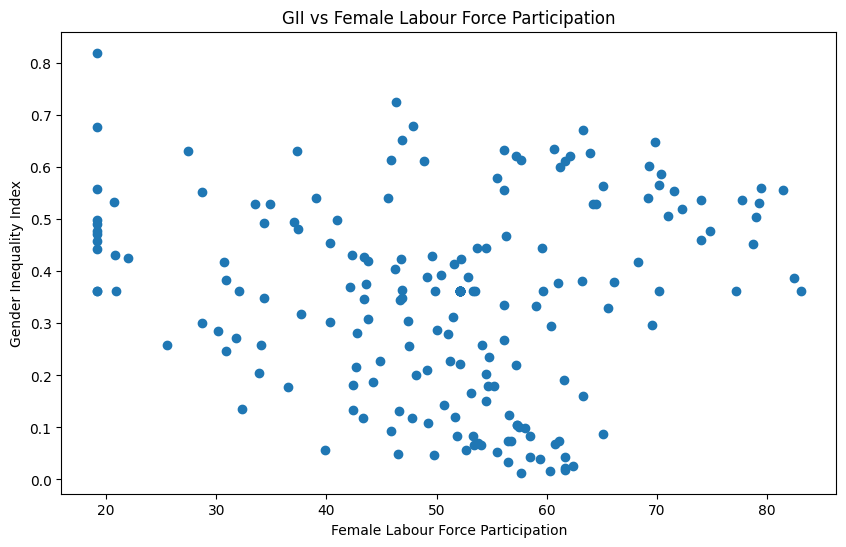

In [36]:
#Visualising the relationship between the GII and F_Labour_force
plt.figure(figsize=(10,6))
plt.scatter(
    data = df,
    x = 'F_Labour_force',
    y = 'GII'
)
plt.title("GII vs Female Labour Force Participation")
plt.xlabel("Female Labour Force Participation")
plt.ylabel("Gender Inequality Index")
plt.show()

In [37]:
df[['GII','F_Labour_force']].corr()

,GII,F_Labour_force
GII,1.000000,-0.046067
F_Labour_force,-0.046067,1.000000


Female labour force participation shows a very weak negative correlation (-0.04) with GII, indicating almost no linear association between the two variables in this dataset.

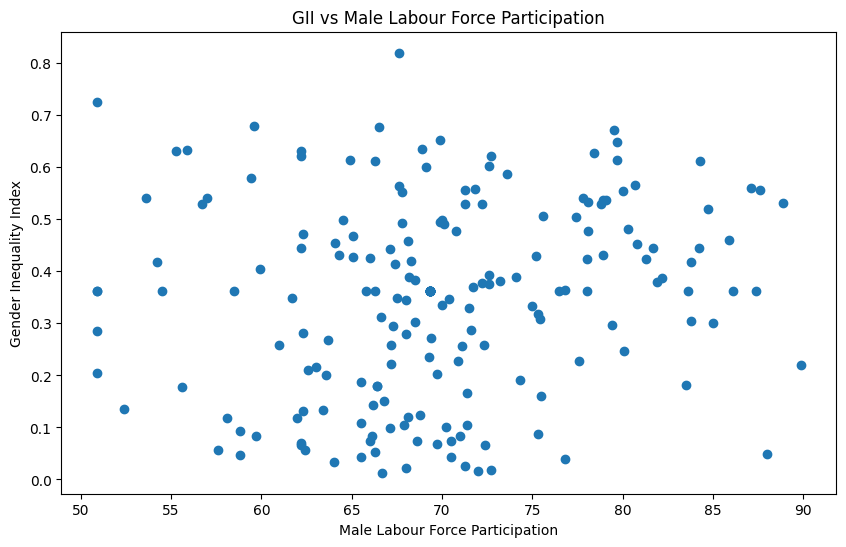

In [38]:
#Visualising the relationship between Male Labour Force Participatio and GII
plt.figure(figsize=(10,6))
plt.scatter(
    data = df,
    x = 'M_Labour_force',
    y = 'GII'
)
plt.title("GII vs Male Labour Force Participation")
plt.xlabel("Male Labour Force Participation")
plt.ylabel("Gender Inequality Index")
plt.show()

In [39]:
df[['GII','M_Labour_force']].corr()

,GII,M_Labour_force
GII,1.000000,0.151574
M_Labour_force,0.151574,1.000000


1. As male labour force participation increases, GII tend to increase slighly.
2. However, the relationship is extremely weak.
3. Male labour force participation alone does not show a meaningful linear relationhsip with GII in your dataset.

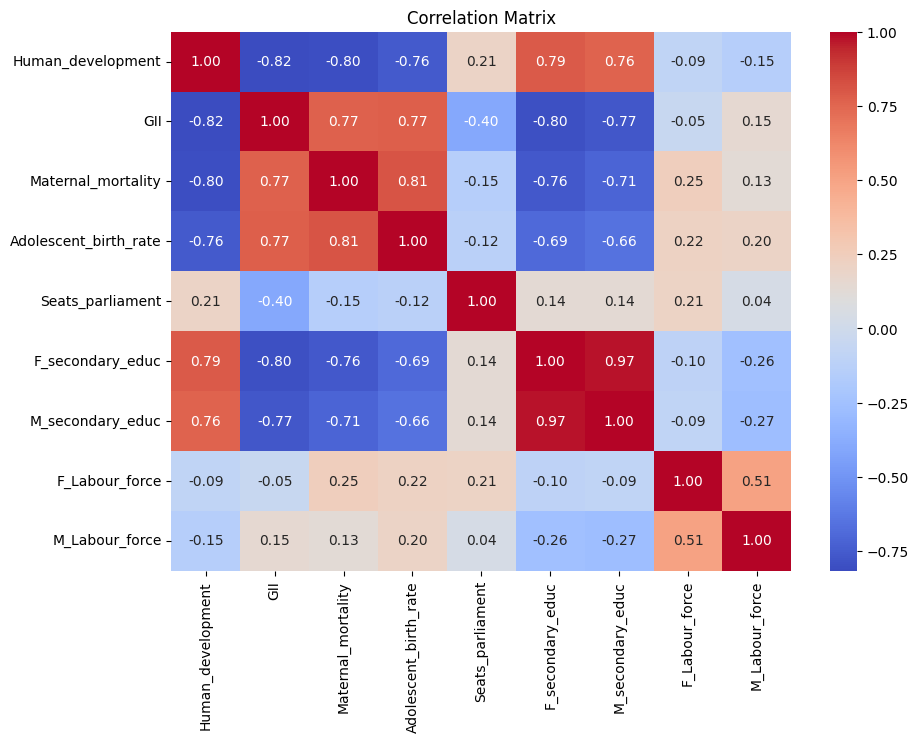

In [40]:
#Visualising correlation heatmap for numerical columns
correlation = df.drop(columns=['Country']).corr()
plt.figure(figsize=(10,7))
sns.heatmap(correlation, annot= True, cmap='coolwarm',fmt='.2f')
plt.title("Correlation Matrix")
plt.show()

In [41]:
#Calculate correlation matrix
correlation = df.drop(columns=['Country']).corr()
print(correlation.round(2))

                       Human_development   GII  Maternal_mortality  \
Human_development                   1.00 -0.82               -0.80   
GII                                -0.82  1.00                0.77   
Maternal_mortality                 -0.80  0.77                1.00   
Adolescent_birth_rate              -0.76  0.77                0.81   
Seats_parliament                    0.21 -0.40               -0.15   
F_secondary_educ                    0.79 -0.80               -0.76   
M_secondary_educ                    0.76 -0.77               -0.71   
F_Labour_force                     -0.09 -0.05                0.25   
M_Labour_force                     -0.15  0.15                0.13   

                       Adolescent_birth_rate  Seats_parliament  \
Human_development                      -0.76              0.21   
GII                                     0.77             -0.40   
Maternal_mortality                      0.81             -0.15   
Adolescent_birth_rate              

In [42]:
#Visualising highly correlated pairs
#Get only the upper traingle to avoid duplicate pairs
upper_traingle = correlation.where(
    np.triu(np.ones(correlation.shape), k=1).astype(bool)
)

#Find pairs with correlation above 0.80 or below -0.80
high_corr = upper_traingle.stack()
high_corr = high_corr[high_corr.abs()> 0.80]
print(high_corr)

Human_development   GII                     -0.816214
                    Maternal_mortality      -0.803867
Maternal_mortality  Adolescent_birth_rate    0.810448
F_secondary_educ    M_secondary_educ         0.972964
dtype: float64


In [43]:
#VIF : Check whether a feature can be explained by other features collectively
from statsmodels.stats.outliers_influence import variance_inflation_factor

x = df.drop(columns=['Country'])
vif_data = pd.DataFrame()
vif_data['Feature'] = x.columns
vif_data['VIF'] =[
    variance_inflation_factor(x.values, i )
    for i in range(x.shape[1])
]
print(vif_data.sort_values(by='VIF', ascending=False))

                 Feature        VIF
5       F_secondary_educ  23.657714
6       M_secondary_educ  19.669035
1                    GII   6.591186
2     Maternal_mortality   5.034024
0      Human_development   4.264924
3  Adolescent_birth_rate   3.907580
7         F_Labour_force   1.898637
8         M_Labour_force   1.616953
4       Seats_parliament   1.453296


# Feature Selection

In [44]:
#dropping object type column
features = df.drop(columns=['Country'])
print(features.shape)
print(features.columns.tolist())

(195, 9)
['Human_development', 'GII', 'Maternal_mortality', 'Adolescent_birth_rate', 'Seats_parliament', 'F_secondary_educ', 'M_secondary_educ', 'F_Labour_force', 'M_Labour_force']


In [45]:
#Comparing M_Secondary_educ and F_secondary_educ
features['Education_Gap'] = (
    features['M_secondary_educ'] - features['F_secondary_educ']
)
print(features[['F_secondary_educ',
                'M_secondary_educ',
                'Education_Gap']].head(10))

   F_secondary_educ  M_secondary_educ  Education_Gap
0              96.9              97.5            0.6
1              99.1              99.3            0.2
2              99.8              99.7           -0.1
3              77.1              83.4            6.3
4              94.6              94.4           -0.2
5              95.1              95.2            0.1
6              91.8              92.2            0.4
7              88.1              86.0           -2.1
8              96.1              96.5            0.4
9              89.8              92.7            2.9


In [46]:
#Check the distribution of Education_Gap
features['Education_Gap'].describe()

,Education_Gap
count,195.000000
mean,4.078974
std,6.881000
min,-25.400000
25%,0.200000
50%,2.400000
75%,7.700000
max,28.800000


In [47]:
features['Education_Gap'].abs().mean()

np.float64(5.622564102564102)

In [48]:
features = features.drop(columns=['Education_Gap'], errors = 'ignore')

In [49]:
#StandardScaler
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

In [50]:
scaled_df = pd.DataFrame(
    scaled_features,
    columns = features.columns,
    index = features.index
)
print(scaled_df.shape)

(195, 9)


In [51]:
print(features.columns.tolist())

['Human_development', 'GII', 'Maternal_mortality', 'Adolescent_birth_rate', 'Seats_parliament', 'F_secondary_educ', 'M_secondary_educ', 'F_Labour_force', 'M_Labour_force']


In [52]:
print(features.shape)

(195, 9)


In [53]:
print(features.columns.tolist())

['Human_development', 'GII', 'Maternal_mortality', 'Adolescent_birth_rate', 'Seats_parliament', 'F_secondary_educ', 'M_secondary_educ', 'F_Labour_force', 'M_Labour_force']


In [54]:
scaled_df.describe().round(2)

,Human_development,GII,Maternal_mortality,Adolescent_birth_rate,Seats_parliament,F_secondary_educ,M_secondary_educ,F_Labour_force,M_Labour_force
count,195.00,195.00,195.00,195.00,195.00,195.00,195.00,195.00,195.00
mean,0.00,0.00,0.00,-0.00,-0.00,0.00,0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.65,-1.82,-0.83,-1.14,-2.01,-2.03,-2.16,-2.15,-2.30
25%,-0.73,-0.79,-0.74,-0.90,-0.66,-0.80,-0.73,-0.50,-0.53
50%,0.18,0.09,-0.49,-0.22,-0.09,0.23,0.15,0.10,-0.07
75%,1.09,0.76,0.38,0.54,0.71,0.89,0.95,0.61,0.65
max,1.09,2.58,2.06,2.69,2.52,1.30,1.29,2.22,2.41


In [55]:
#PCA
from sklearn.decomposition import PCA
pca = PCA()
pca.fit(scaled_df)
explained_variance = pca.explained_variance_ratio_
print(explained_variance)

[0.55752054 0.17606001 0.10038985 0.07091938 0.0397523  0.02279052
 0.01704975 0.01285696 0.0026607 ]


In [56]:
#Calculate cumulative explained variance
cumulative_variance = np.cumsum(explained_variance)
print(cumulative_variance)

[0.55752054 0.73358055 0.8339704  0.90488978 0.94464207 0.96743259
 0.98448234 0.9973393  1.        ]


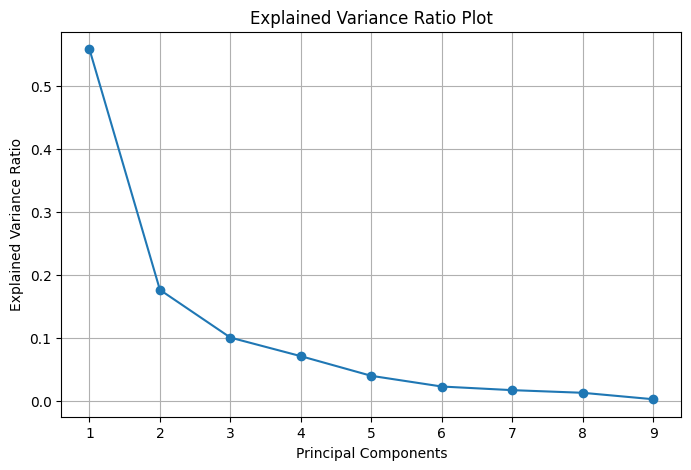

In [57]:
#Visualising the explained varaince using scree plot
plt.figure(figsize=(8,5))
plt.plot(range(1,10), explained_variance, marker = 'o')
plt.xlabel('Principal Components')
plt.ylabel('Explained Variance Ratio')
plt.title("Explained Variance Ratio Plot")
plt.xticks(range(1,10))
plt.grid()
plt.show()

In [58]:
#Transform data , retain 4 components
pca = PCA(n_components=4)
pca_features = pca.fit_transform(scaled_df)
pca_df = pd.DataFrame(
    pca_features,
    columns =['PC1','PC2','PC3','PC4']
)
print(pca_df.head())
print(pca_df.shape)

        PC1       PC2       PC3       PC4
0  2.929918  1.562042  0.392511  0.100804
1  3.067025  1.628289  0.778159  0.050983
2  3.024907  1.654705  1.017993  0.178661
3  1.530268 -0.193341 -0.255237  0.118465
4  2.680781  1.269393  0.403850  0.207753
(195, 4)


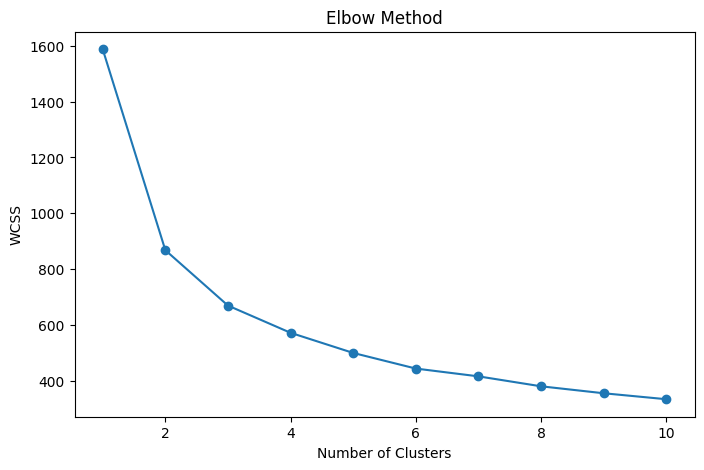

In [59]:
#Apply Elbow Method
from sklearn.cluster import KMeans
wcss = []
for k in range(1,11):
  kmeans = KMeans(n_clusters =k, random_state=42, n_init=10)
  kmeans.fit(pca_df)
  wcss.append(kmeans.inertia_)
plt.figure(figsize=(8,5))
plt.plot(range(1,11), wcss, marker ='o')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

In [60]:
print(wcss)

[1588.0815601299469, 867.5438712532487, 668.9432709319544, 571.3083749610752, 499.1135626588299, 443.101558085441, 415.17096457474105, 379.5033324043604, 354.5621396472361, 333.19999018702947]


In [61]:
#Silhouette Score
from sklearn.metrics import silhouette_score
silhouette_scores = []
for k in range(2,11):
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  labels=kmeans.fit_predict(pca_df)

  score = silhouette_score(pca_df, labels)
  silhouette_scores.append(score)
print(silhouette_scores)

[np.float64(0.4041357090991574), np.float64(0.3123539741488045), np.float64(0.2818304663965409), np.float64(0.26854190771999925), np.float64(0.2640103092811652), np.float64(0.26320273458105603), np.float64(0.22522097651798006), np.float64(0.22661892065701053), np.float64(0.23029695544635387)]


In [62]:
#Building model on 2 clusters and 3 clusters
kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init=10)
cluster_2 = kmeans_2.fit_predict(pca_df)

kmeans_3 = KMeans(n_clusters=3, random_state = 42, n_init=10)
cluster_3 = kmeans_3.fit_predict(pca_df)

print("K-2 Cluster Distribution: ")
print(pd.Series(cluster_2).value_counts().sort_index())

print("\nK-3 Cluster Distribution: ")
print(pd.Series(cluster_3).value_counts().sort_index())

K-2 Cluster Distribution: 
0    127
1     68
Name: count, dtype: int64

K-3 Cluster Distribution: 
0    87
1    45
2    63
Name: count, dtype: int64


In [63]:
#Understand the actual country groups for K=2
clustered_df = df.copy()
clustered_df['Cluster'] = cluster_2
clustered_df.groupby('Cluster').mean(numeric_only=True).round(2)

,Human_development,GII,Maternal_mortality,Adolescent_birth_rate,Seats_parliament,F_secondary_educ,M_secondary_educ,F_Labour_force,M_Labour_force
Cluster,,,,,,,,,
0,3.45,0.25,42.77,25.19,25.66,80.56,82.08,48.23,68.08
1,1.60,0.53,276.28,79.82,22.87,31.27,40.13,55.12,73.30


1. Countries with relatively higher human development and lower gender inequality.
2. Countries with relatively lower human development and higher gender inequality.

In [64]:
#Examining K=3
clustered_df = df.copy()
clustered_df['Cluster'] = cluster_3
clustered_df.groupby('Cluster').mean(numeric_only=True).round(2)

,Human_development,GII,Maternal_mortality,Adolescent_birth_rate,Seats_parliament,F_secondary_educ,M_secondary_educ,F_Labour_force,M_Labour_force
Cluster,,,,,,,,,
0,3.71,0.19,22.21,17.02,30.01,85.74,87.79,52.23,68.81
1,1.36,0.56,353.45,93.18,23.96,27.40,37.94,62.36,74.37
2,2.59,0.42,101.30,46.88,17.87,58.17,60.43,40.05,68.22


For now, K=2 is statistically better according to the Silhouette score, while K=3 provides more detailed and interesting country profiles.

In [65]:
#Get the country names for each cluster of K=2
clustered_df = df[['Country']].copy()
clustered_df['Cluster'] = cluster_2
for cluster in sorted(clustered_df['Cluster'].unique()):
  print(f"Cluster {cluster}: ")
  print(clustered_df[clustered_df['Cluster'] == cluster]['Country'].tolist())

Cluster 0: 
['Switzerland', 'Norway', 'Iceland', 'Hong Kong', 'Australia', 'Denmark', 'Sweden', 'Ireland', 'Germany', 'Netherlands', 'Finland', 'Singapore', 'Belgium', 'New Zealand', 'Canada', 'Liechtenstein', 'Luxembourg', 'United Kingdom', 'Japan', 'South Korea', 'United States', 'Israel', 'Malta', 'Slovenia', 'Austria', 'United Arab Emirates', 'Spain', 'France', 'Cyprus', 'Italy', 'Estonia', 'Czechia', 'Greece', 'Poland', 'Bahrain', 'Lithuania', 'Saudi Arabia', 'Portugal', 'Latvia', 'Andorra', 'Croatia', 'Chile', 'Qatar', 'San Marino', 'Slovakia', 'Hungary', 'Argentina', 'Türkiye', 'Montenegro', 'Kuwait', 'Brunei Darussalam', 'Russian Federation', 'Romania', 'Oman', 'Bahamas', 'Kazakhstan', 'Trinidad and Tobago', 'Costa Rica', 'Uruguay', 'Belarus', 'Panama', 'Malaysia', 'Georgia', 'Mauritius', 'Serbia', 'Thailand', 'Albania', 'Bulgaria', 'Grenada', 'Barbados', 'Antigua and Barbuda', 'Seychelles', 'Sri Lanka', 'Bosnia and Herzegovina', 'Saint Kitts and Nevis', 'Iran', 'Ukraine', 'Nor

In [66]:
#Saving the cluster assignments
final_df = df.copy()
final_df['Cluster'] = cluster_2
final_df[['Country','Cluster']].to_csv(
    'GII_KMeans_Cluster_Results.csv',
    index=False
)

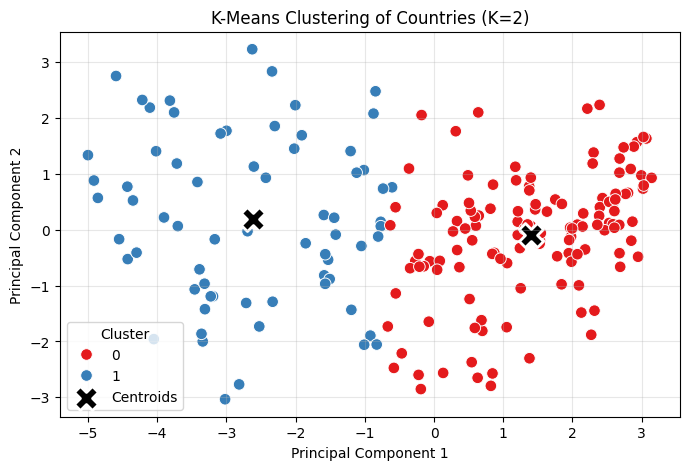

In [67]:
#Create 2D Cluster Visualisation
plt.figure(figsize=(8,5))
sns.scatterplot(
    x = pca_df['PC1'],
    y = pca_df['PC2'],
    hue = cluster_2,
    palette = 'Set1',
    s=70
)

#Centroids
centroids = kmeans_2.cluster_centers_
plt.scatter(
    centroids[:,0],
    centroids[:,1],
    marker ='X',
    s = 300,
    color='black',
    edgecolor='white',
    linewidth=2,
    label = 'Centroids'
)
plt.title("K-Means Clustering of Countries (K=2)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title='Cluster')
plt.grid(alpha=0.3)
plt.show()

The K-Means model has idnetified two reasonably distinct groups of countries in the PCA transformed feature scope.

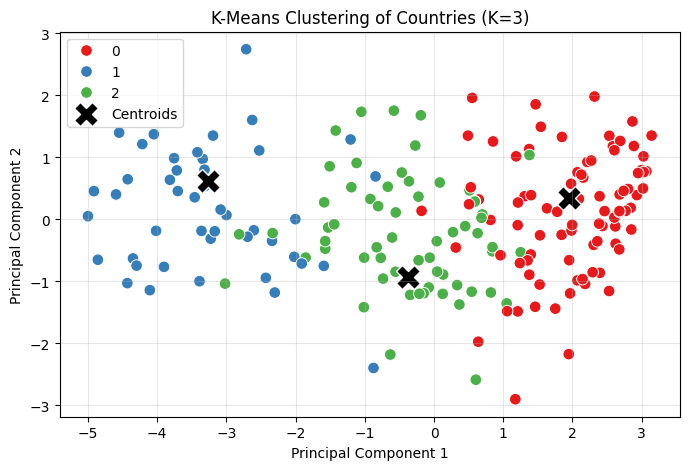

In [68]:
#Visualising K=3
plt.figure(figsize=(8,5))

#Plot countries
sns.scatterplot(
    x = pca_df['PC1'],
    y = pca_df['PC3'],
    hue = cluster_3,
    palette = 'Set1',
    s = 70
)

#Centroids
centroids_3= kmeans_3.cluster_centers_

#Plot centroids
plt.scatter(
    centroids_3[:, 0],
    centroids_3[:, 1],
    marker ='X',
    s = 300,
    color = 'black',
    edgecolor = 'white',
    label = 'Centroids'
)

plt.title("K-Means Clustering of Countries (K=3)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(alpha = 0.3)
plt.show()

K-Means Clustering was performed using the PCA- transformed dataset. Both K=2 and K=3 were evaluated using the Elbow Method, Silhouette Score, cluster distribution and visualisation. K=2 was selected because it achieved a higher silhouette score of 0.4041
and provided a clearer, more interpretable separation of countries into two broad groups based on their gender inequality indicators.

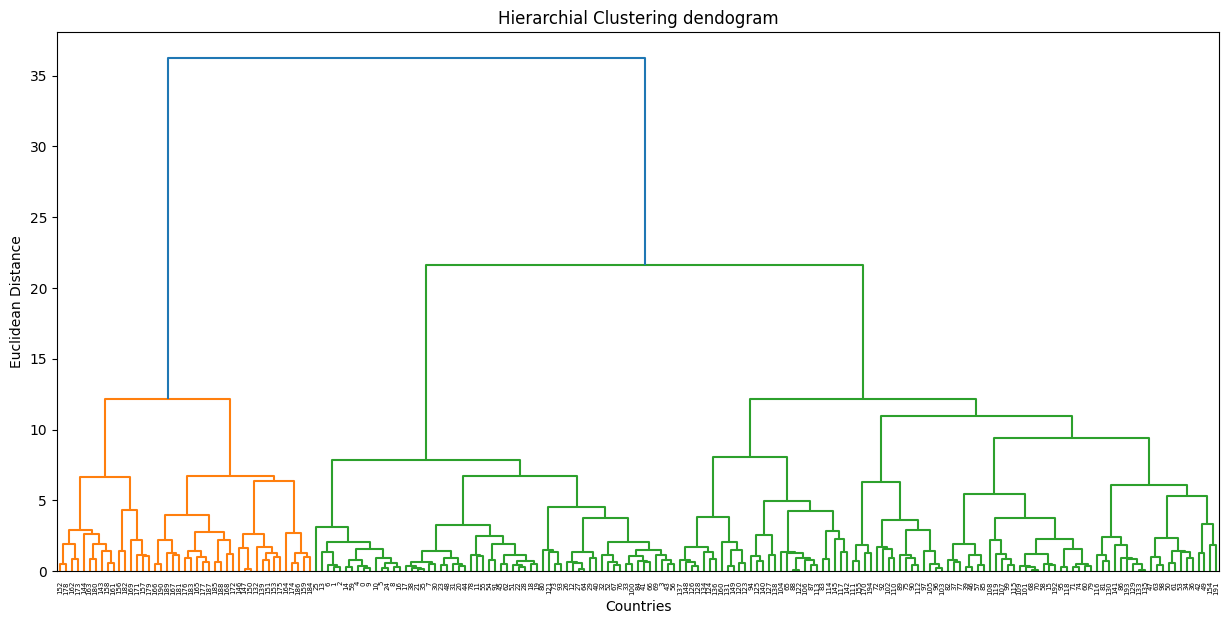

In [69]:
#Hierarchial Clustering with pca
import scipy.cluster.hierarchy as sch
plt.figure(figsize=(15,7))
dendrogram = sch.dendrogram(
    sch.linkage(
        pca_df,
        method = 'ward'
    )
)
plt.title("Hierarchial Clustering dendogram")
plt.xlabel("Countries")
plt.ylabel("Euclidean Distance")
plt.show()

In [70]:
#Hierarchial Clustering with K=2
from sklearn.cluster import AgglomerativeClustering
hc = AgglomerativeClustering(n_clusters = 2, linkage ='ward')
hc_clusters = hc.fit_predict(pca_df)
pd.Series(hc_clusters).value_counts().sort_index()

,count
0,152
1,43


For this. I'll keep K-MEans with K=2 as the preferred model because:
1. It achieved a higher silhouette score (0.4041).
2. Its cluster distribution (127 and 68) is more balanced.
3. Its two clusters were easier to understand and interpret.

In [71]:
#Test K-Means without GII
features_no_gii = df.drop(columns=['Country','GII'])
features_no_gii.shape

(195, 8)

In [72]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler_no_gii = StandardScaler()

scaled_no_gii = scaler_no_gii.fit_transform(features_no_gii)

pca_no_gii = PCA(n_components=0.90)

pca_features_no_gii = pca_no_gii.fit_transform(scaled_no_gii)

pca_df_no_gii = pd.DataFrame(pca_features_no_gii)

print("PCA Shape:", pca_df_no_gii.shape)
print("Explained Variance:", pca_no_gii.explained_variance_ratio_.sum())

PCA Shape: (195, 4)
Explained Variance: 0.9094031738052696


In [73]:
#Calculate Sillhouette score
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
silhouette_scores_no_gii = []
for k in range(2, 11):
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  labels = kmeans.fit_predict(pca_df_no_gii)
  score = silhouette_score(pca_df_no_gii, labels)
  silhouette_scores_no_gii.append(score)
  print(f"K={k}: Silhouette Score = {score: .4f}")

K=2: Silhouette Score =  0.4143
K=3: Silhouette Score =  0.3055
K=4: Silhouette Score =  0.2696
K=5: Silhouette Score =  0.2642
K=6: Silhouette Score =  0.2623
K=7: Silhouette Score =  0.2634
K=8: Silhouette Score =  0.2457
K=9: Silhouette Score =  0.2494
K=10: Silhouette Score =  0.2383


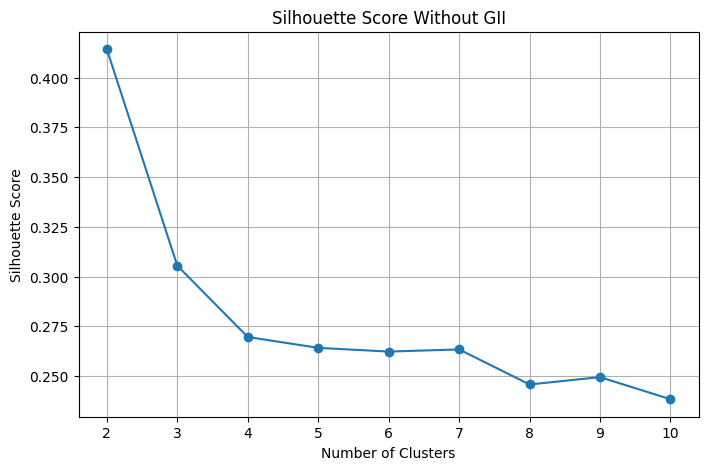

In [74]:
#Plot the Silhouette score
plt.figure(figsize=(8,5))
plt.plot(range(2,11), silhouette_scores_no_gii, marker ='o')
plt.title("Silhouette Score Without GII")
plt.xlabel("Number of Clusters")
plt.ylabel('Silhouette Score')
plt.xticks(range(2,11))
plt.grid()
plt.show()

The Model Without GII has a slightly higher score, but the imrovement is very small.
Thats why I'll select the K-2 with GII as the final model

In [75]:
#Display Country in Cluster 0
cluster_0_countries = final_df[final_df['Cluster'] == 0]['Country'].tolist()
print("Cluster 0 Countries: ")
print(cluster_0_countries)
print("Total Countries: ", len(cluster_0_countries))

Cluster 0 Countries: 
['Switzerland', 'Norway', 'Iceland', 'Hong Kong', 'Australia', 'Denmark', 'Sweden', 'Ireland', 'Germany', 'Netherlands', 'Finland', 'Singapore', 'Belgium', 'New Zealand', 'Canada', 'Liechtenstein', 'Luxembourg', 'United Kingdom', 'Japan', 'South Korea', 'United States', 'Israel', 'Malta', 'Slovenia', 'Austria', 'United Arab Emirates', 'Spain', 'France', 'Cyprus', 'Italy', 'Estonia', 'Czechia', 'Greece', 'Poland', 'Bahrain', 'Lithuania', 'Saudi Arabia', 'Portugal', 'Latvia', 'Andorra', 'Croatia', 'Chile', 'Qatar', 'San Marino', 'Slovakia', 'Hungary', 'Argentina', 'Türkiye', 'Montenegro', 'Kuwait', 'Brunei Darussalam', 'Russian Federation', 'Romania', 'Oman', 'Bahamas', 'Kazakhstan', 'Trinidad and Tobago', 'Costa Rica', 'Uruguay', 'Belarus', 'Panama', 'Malaysia', 'Georgia', 'Mauritius', 'Serbia', 'Thailand', 'Albania', 'Bulgaria', 'Grenada', 'Barbados', 'Antigua and Barbuda', 'Seychelles', 'Sri Lanka', 'Bosnia and Herzegovina', 'Saint Kitts and Nevis', 'Iran', 'Ukra

In [76]:
#Display Country in Cluster 1
cluster_1_countries = final_df[final_df['Cluster'] == 1]['Country'].tolist()
print("Cluster 1 Countries: ")
print(cluster_1_countries)
print("Total Countries: ", len(cluster_1_countries))

Cluster 1 Countries: 
['Saint Vincent and the Grenadines', 'Paraguay', 'Saint Lucia', 'Indonesia', 'Bolivia', 'Iraq', 'Belize', 'Morocco', 'El Salvador', 'Nicaragua', 'Bhutan', 'Cabo Verde', 'Bangladesh', 'India', 'Ghana', 'Guatemala', 'Honduras', 'Sao Tome and Principe', 'Namibia', "Lao People's Democratic Republic", 'Timor-Leste', 'Nepal', 'Eswatini', 'Equatorial Guinea', 'Cambodia', 'Zimbabwe', 'Angola', 'Myanmar', 'Syrian Arab Republic', 'Cameroon', 'Kenya', 'Congo', 'Zambia', 'Solomon Islands', 'Papua New Guinea', 'Mauritania', "Côte d'Ivoire", 'Tanzania', 'Pakistan', 'Togo', 'Haiti', 'Nigeria', 'Rwanda', 'Benin', 'Uganda', 'Lesotho', 'Malawi', 'Senegal', 'Sudan', 'Madagascar', 'Gambia', 'Ethiopia', 'Eritrea', 'Guinea-Bissau', 'Liberia', 'Congo', 'Afghanistan', 'Sierra Leone', 'Guinea', 'Yemen', 'Burkina Faso', 'Mozambique', 'Mali', 'Burundi', 'Central African Republic', 'Niger', 'Chad', 'South Sudan']
Total Countries:  68


In [77]:
import joblib
import os
os.makedirs('GII_Deployment', exist_ok = True)

#Save Standard Scaler
joblib.dump(scaler, 'GII_Deployment/scaler.pkl')

#Save the PCA Model
joblib.dump(pca, 'GII_Deployment/pca.pkl')

#Save the K-Means Model
joblib.dump(kmeans_2, 'GII_Deployment/kmeans.pkl')

#Save the final dataset with cluster labels
final_df.to_csv('GII_Deployment/GII_Final_Dataset.csv', index=False)

print("All model files saves successfully")

All model files saves successfully
